Vamos a probar el tamaño de los datasets para ver si podemos extraer información nueva

In [4]:
%pip install pandas
%pip install pyarrow
%pip install pyreadr
%pip install numpy
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [5]:
!python --version
!python -m pip --version
!python -m pip show numpy pandas

Python 3.11.9
pip 26.2.1 from c:\Users\mazar\Desktop\Diablos\.venv\Lib\site-packages\pip (python 3.11)

Name: numpy
Version: 2.2.6
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License: Copyright (c) 2005-2024, NumPy Developers.
 All rights reserved.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions are
 met:

     * Redistributions of source code must retain the above copyright
        notice, this list of conditions and the following disclaimer.

     * Redistributions in binary form must reproduce the above
        copyright notice, this list of conditions and the following
        disclaimer in the documentation and/or other materials provided
        with the distribution.

     * Neither the name of the NumPy Developers nor the names of any
        contributors may be used to endorse or promote products d

In [7]:
from pathlib import Path
import pandas as pd
import pyreadr

df_parquet = pd.read_parquet('./Dataset/stuff_model_df.parquet')
df_pkl = pd.read_pickle('./Dataset/stuff_model_df.pkl')
df_rds = pyreadr.read_r('./Dataset/stuff_model_df.rds')

In [8]:
df_parquet.head(1)

,year,PitchUID,game_anon_id,pitcher_anon_id,batter_anon_id,catcher_anon_id,PitcherThrows,BatterSide,altitude_category,AutoPitchType,...,Top/Bottom,Outs,Balls,Strikes,count,PlateLocHeight,PlateLocSide,in_strike_zone,outside_strike_zone,swung_outside_strike_zone
0,2024,d6a82560-f939-11ee-8e28-698264036ef0,game_001331,pitcher_01067,batter_00272,catcher_00123,Left,Right,No Altitude,Sinker,...,Top,0.0,0.0,0.0,0-0,4.19842,-1.06959,0,1.0,0.0


In [9]:
df_pkl.head(1)

,year,PitchUID,game_anon_id,pitcher_anon_id,batter_anon_id,catcher_anon_id,PitcherThrows,BatterSide,altitude_category,AutoPitchType,...,Top/Bottom,Outs,Balls,Strikes,count,PlateLocHeight,PlateLocSide,in_strike_zone,outside_strike_zone,swung_outside_strike_zone
0,2024,d6a82560-f939-11ee-8e28-698264036ef0,game_001331,pitcher_01067,batter_00272,catcher_00123,Left,Right,No Altitude,Sinker,...,Top,0.0,0.0,0.0,0-0,4.19842,-1.06959,0,1.0,0.0


In [10]:
df_rds

OrderedDict([(None,
                      year                              PitchUID game_anon_id  \
              0       2024  d6a82560-f939-11ee-8e28-698264036ef0  game_001331   
              1       2024  df15bd20-f939-11ee-8e28-698264036ef0  game_001331   
              2       2024  e965d080-f939-11ee-8e28-698264036ef0  game_001331   
              3       2024  f1128940-f939-11ee-8e28-698264036ef0  game_001331   
              4       2024  ffee8d60-f939-11ee-8e28-698264036ef0  game_001331   
              ...      ...                                   ...          ...   
              634997  2026  6ca6ae90-66db-11f1-bbc5-8ded59fb6515  game_001675   
              634998  2026  7708ea60-66db-11f1-bbc5-8ded59fb6515  game_001675   
              634999  2026  8f3ebb00-66db-11f1-bbc5-8ded59fb6515  game_001675   
              635000  2026  96a6c9a0-66db-11f1-bbc5-8ded59fb6515  game_001675   
              635001  2026  a0e46670-66db-11f1-bbc5-8ded59fb6515  game_001675   
        

In [11]:
import pandas as pd

dictionary = pd.read_csv('./Dataset/stuff_plus_data_dictionary.csv', sep=',')
print(dictionary.keys())

Index(['column_name', 'definition', 'data_type', 'unit_or_values', 'category',
       'feature_role', 'use_as_model_feature', 'notes'],
      dtype='object')


In [12]:
dictionary_by_column = dictionary.set_index('column_name')

for column in df_parquet.columns:
    print('=' * 80)
    print(f'Column name: {column}')
    print(f'Data type: {df_parquet[column].dtype}')

    if column in dictionary_by_column.index:
        info = dictionary_by_column.loc[column]
        print(f"Definition: {info['definition']}")
        print(f"Unit or values: {info['unit_or_values']}")
        print(f"Feature role: {info['feature_role']}")
        print(f"Use as model feature: {info['use_as_model_feature']}")
        print(f"Notes: {info['notes']}")
    else:
        print('Definition: Not available in the data dictionary')
        print('Unit or values: Not available in the data dictionary')
        print('Feature role: Not available in the data dictionary')
        print('Use as model feature: Not available in the data dictionary')
        print('Notes: Not available in the data dictionary')

    unique_count = df_parquet[column].nunique(dropna=False)
    print(f'Unique value count: {unique_count}')
    if unique_count < 20:
        print('Unique values:')
        print(df_parquet[column].value_counts(dropna=False).to_string())
    else:
        print('Unique values: omitted')

Column name: year
Data type: int32
Definition: Season year extracted from the local pitch date.
Unit or values: YYYY
Feature role: context_only
Use as model feature: Yes, for season normalization or splits only
Notes: Derived from Trackman Date. Useful for train/test splits and season-level calibration.
Unique value count: 3
Unique values:
year
2025    256144
2024    243254
2026    135604
Column name: PitchUID
Data type: object
Definition: Unique pitch identifier for the pitch event.
Unit or values: GUID / unique ID
Feature role: id_only
Use as model feature: No
Notes: Use only to return predictions and join results back internally. Do not use as a model input.
Unique value count: 635002
Unique values: omitted
Column name: game_anon_id
Data type: object
Definition: Anonymous game identifier created by Diablos for the hackathon dataset.
Unit or values: game_######
Feature role: grouping_only
Use as model feature: No
Notes: Use for grouping, validation splits, or aggregation only. Do not

In [13]:
df_parquet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 635002 entries, 0 to 635001
Data columns (total 84 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   year                       635002 non-null  int32   
 1   PitchUID                   635002 non-null  object  
 2   game_anon_id               635002 non-null  object  
 3   pitcher_anon_id            631730 non-null  object  
 4   batter_anon_id             632982 non-null  object  
 5   catcher_anon_id            632677 non-null  object  
 6   PitcherThrows              633841 non-null  object  
 7   BatterSide                 634018 non-null  object  
 8   altitude_category          631982 non-null  object  
 9   AutoPitchType              635002 non-null  category
 10  RelSpeed                   635002 non-null  float64 
 11  EffectiveVelo              635002 non-null  object  
 12  ZoneSpeed                  635002 non-null  float64 
 13  SpinRate      

In [14]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print(df_pkl.describe(include='all').T.to_string())

                              count  unique                                   top    freq         mean         std         min          25%          50%          75%          max
year                       635002.0     NaN                                   NaN     NaN  2024.830473    0.753582      2024.0       2024.0       2025.0       2025.0       2026.0
PitchUID                     635002  635002  a0e46670-66db-11f1-bbc5-8ded59fb6515       1          NaN         NaN         NaN          NaN          NaN          NaN          NaN
game_anon_id                 635002    2127                           game_001513     546          NaN         NaN         NaN          NaN          NaN          NaN          NaN
pitcher_anon_id              631730    1134                         pitcher_00938    4222          NaN         NaN         NaN          NaN          NaN          NaN          NaN
batter_anon_id               632982     864                          batter_00815    4133          NaN   

In [15]:
# Dimensiones
print(df_parquet.shape)

# Tipos de datos
print(df_parquet.dtypes.value_counts())

# Valores faltantes
missing = df_parquet.isna().sum().sort_values(ascending=False)
print(missing.head(20))

# Porcentaje de valores faltantes
missing_pct = (df_parquet.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(20))

# Variables constantes
print(df_parquet.nunique().sort_values().head(20))

(635002, 84)
float64     65
object      13
int32        2
category     1
category     1
category     1
category     1
Name: count, dtype: int64
Distance             493238
Angle                452182
ExitSpeed            452181
Direction            452181
hit_type             450965
pitcher_anon_id        3272
altitude_category      3020
catcher_anon_id        2325
batter_anon_id         2020
PitcherThrows          1161
BatterSide              984
Extension               773
SpinAxis                702
HorzBreak               702
InducedVertBreak        702
Tilt                    702
VertBreak               702
SpinRate                 80
game_anon_id              0
year                      0
dtype: int64
Distance             77.675031
Angle                71.209539
ExitSpeed            71.209382
Direction            71.209382
hit_type             71.017887
pitcher_anon_id       0.515274
altitude_category     0.475589
catcher_anon_id       0.366141
batter_anon_id        0.318109
Pitc

In [16]:
missing = pd.DataFrame({
    "n_missing": df_parquet.isna().sum(),
    "pct_missing": df_parquet.isna().mean() * 100
}).sort_values("pct_missing", ascending=False)

missing.head(20)

,n_missing,pct_missing
Distance,493238,77.675031
Angle,452182,71.209539
ExitSpeed,452181,71.209382
Direction,452181,71.209382
hit_type,450965,71.017887
pitcher_anon_id,3272,0.515274
altitude_category,3020,0.475589
catcher_anon_id,2325,0.366141
batter_anon_id,2020,0.318109
PitcherThrows,1161,0.182834


<Axes: >

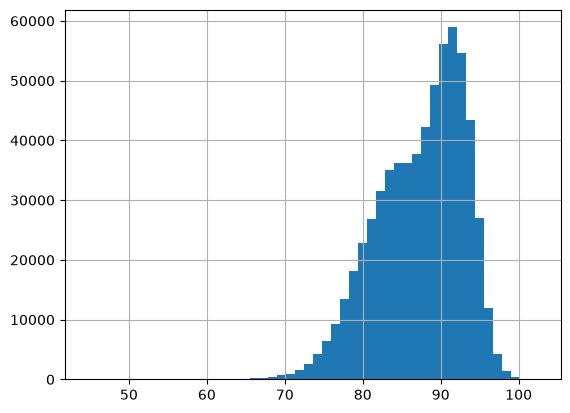

In [17]:
df_parquet["RelSpeed"].hist(bins=50)

<Axes: xlabel='RelSpeed'>

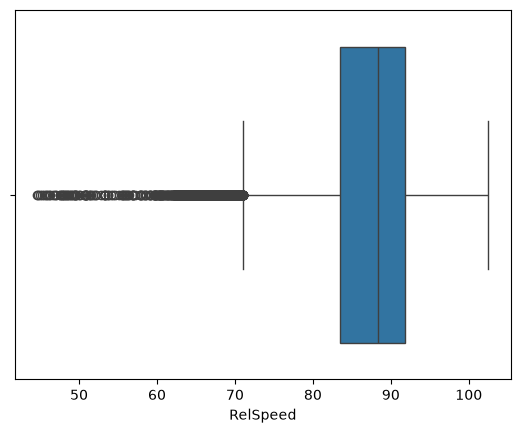

In [23]:
import seaborn as sns
sns.boxplot(x=df_parquet["RelSpeed"])

In [24]:
df_parquet.groupby("AutoPitchType")["RelSpeed"].agg(
    ["count", "mean", "std", "min", "max"]
)

C:\Users\mazar\AppData\Local\Temp\ipykernel_41824\2171784821.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_parquet.groupby("AutoPitchType")["RelSpeed"].agg(


,count,mean,std,min,max
AutoPitchType,,,,,
Changeup,78925,83.193208,3.528533,48.18959,96.67458
Curveball,54024,77.727916,3.625722,44.65569,91.95219
Cutter,26468,88.568705,2.246360,73.23659,99.71627
Four-Seam,217618,91.756786,2.648797,50.93587,102.50375
Other,61,63.813407,4.437155,48.52347,87.04039
Sinker,110897,91.143340,2.583703,67.83957,101.73197
Slider,139129,83.754902,3.005006,47.97331,95.98818
Splitter,7289,83.850592,3.362579,72.52665,94.09538
OneSeamFastBall,1,76.382930,NaN,76.38293,76.38293


In [25]:
df_parquet.groupby("AutoPitchType")["is_swing"].mean()

C:\Users\mazar\AppData\Local\Temp\ipykernel_41824\1334598730.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_parquet.groupby("AutoPitchType")["is_swing"].mean()


AutoPitchType
Changeup           0.489946
Curveball          0.433807
Cutter             0.489157
Four-Seam          0.464332
Other              0.459016
Sinker             0.456595
Slider             0.483106
Splitter           0.513514
OneSeamFastBall    1.000000
Sweeper            0.523810
TwoSeamFastBall    0.000000
Knuckleball        1.000000
Name: is_swing, dtype: float64

In [26]:
df_parquet.groupby("AutoPitchType")["is_whiff"].mean()

C:\Users\mazar\AppData\Local\Temp\ipykernel_41824\294768644.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_parquet.groupby("AutoPitchType")["is_whiff"].mean()


AutoPitchType
Changeup           0.142667
Curveball          0.142881
Cutter             0.109000
Four-Seam          0.091803
Other              0.180328
Sinker             0.066530
Slider             0.153584
Splitter           0.167513
OneSeamFastBall    1.000000
Sweeper            0.156463
TwoSeamFastBall    0.000000
Knuckleball        1.000000
Name: is_whiff, dtype: float64

<Axes: xlabel='PlateLocSide', ylabel='PlateLocHeight'>

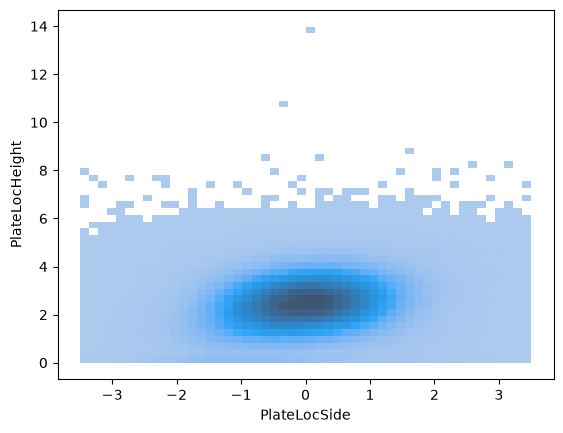

In [27]:
sns.histplot(
    data=df_parquet,
    x="PlateLocSide",
    y="PlateLocHeight",
    bins=50
)

In [28]:
numeric = df_parquet.select_dtypes(include="number")

corr = numeric.corr()

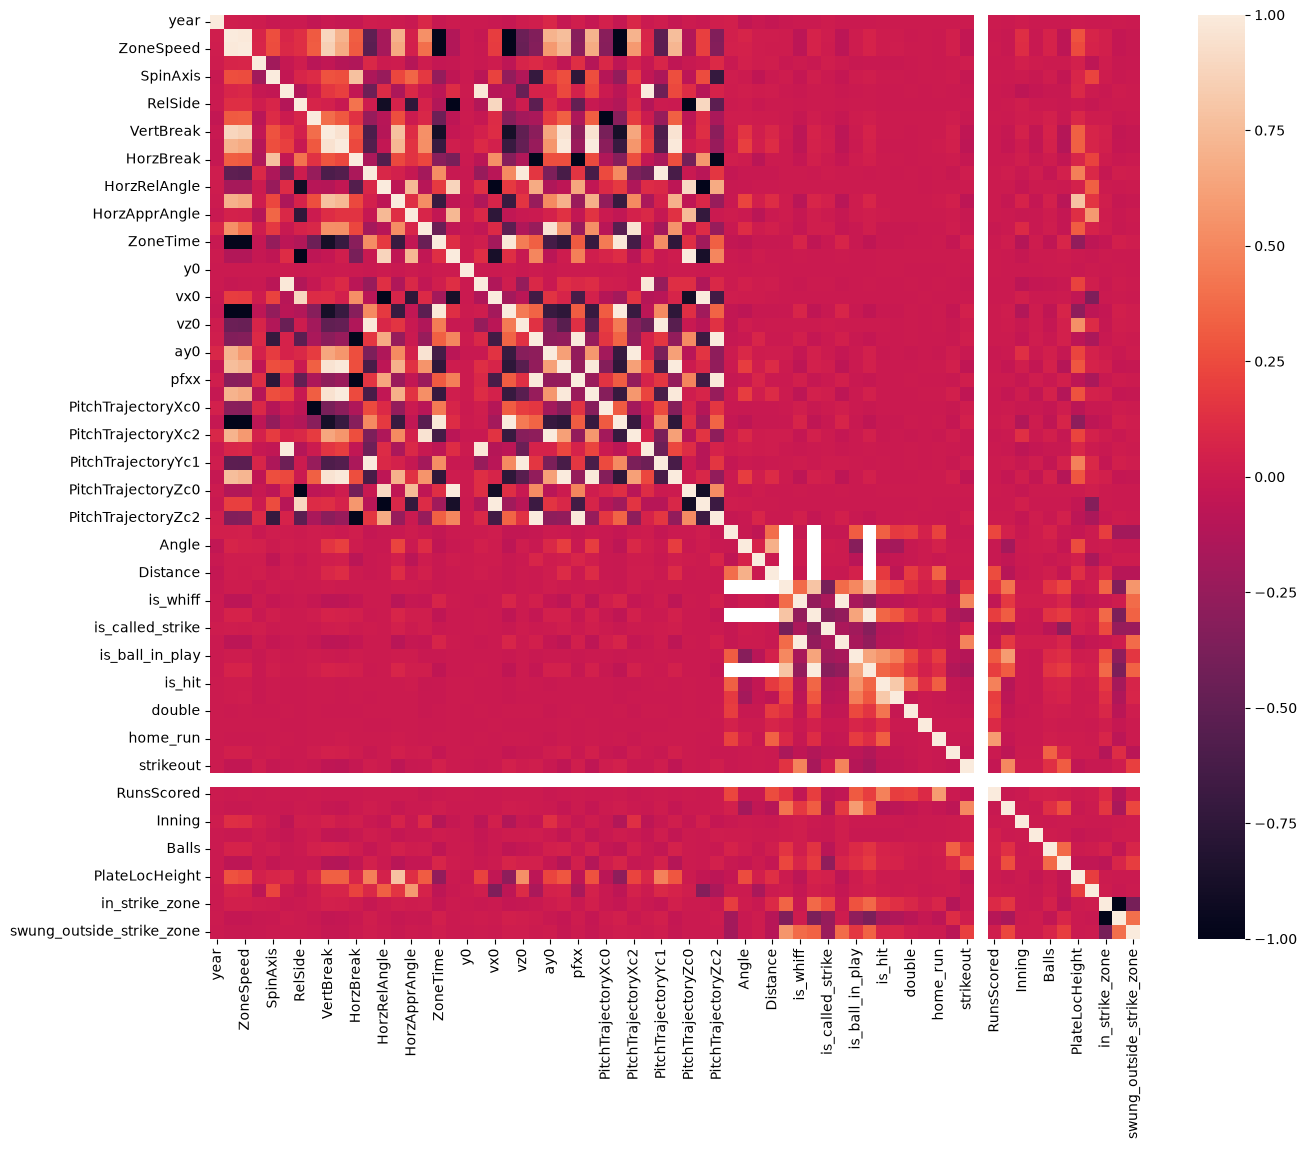

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 12))
sns.heatmap(corr)
plt.show()